# Northern Beaches Water Quality — Predicting Enterococci from Rainfall
ENGG2112 · AI for Good

**Goal:** predict the enterococci count (CFU/100 mL) for a swim site on a given day from **rainfall and site factors only**, then use that to answer two questions:
1. **Is it safe to swim today?** (predicted count below the safe level)
2. **If no more rain falls, how many days until it is safe again?**

This reuses the cleaning and SILO rainfall steps from the original notebook, but changes the model: it is now a **regression** (predicts the count, on a log scale), and it has **no "previous sample" inputs**, so it works from rain alone.

| Section | What happens |
|---|---|
| 0–1 | Imports and settings |
| 2–4 | Data cleaning, label, quick checks (from the original notebook) |
| 5 | Load SILO rainfall, match sites to rain points, build rainfall features (windows up to 30 days, days since rain) |
| 6 | **Lagoon flag** (1 = beach with a lagoon attached) and the model inputs |
| 7 | Split the data (by date by default) |
| 8–9 | Train regression models, pick the best, tune the safe/not-safe cutoff |
| 10 | Final test-set results |
| 11 | **Does the lagoon flag actually help?** (tested over several time periods) |
| 12 | **Days until safe, assuming no more rain** |
| 13 | Back-test the days-until-safe idea against real recoveries |

## 0. Imports

### 0.1 Load libraries
**What it does:** Loads pandas, matplotlib, scikit-learn and XGBoost. If XGBoost is missing, run `pip install xgboost` (and `pip install openpyxl` for the rainfall .xlsx files).

**Output:** Nothing.

In [16]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             recall_score, precision_score, f1_score, confusion_matrix)
from xgboost import XGBRegressor

## 1. Settings

### 1.1 Config
**What it does:** All the settings in one place.
- `THRESHOLD`: poor = enterococci **≥** 41 CFU/100 mL. ⚠️ Check the comparator (≥ vs >) against the NHMRC/Beachwatch source and cite it.
- `RAIN_WINDOWS`: how many days of rain to add up (1, 2, 3, 5, 7, 14, 30). Long windows matter for lagoons, which drain slowly.
- `RAIN_EVENT_MM`: a day with at least this much rain counts as a "rain day" for the *days since rain* feature.
- `USE_LAGOON`, `LAGOON_KEYWORDS`, `LAGOON_EXACT`, `LAGOON_EXCLUDE`: control the lagoon flag (Section 6.1). ⚠️ The default keywords are my guess at which beaches have a lagoon attached. **Check the table printed in 6.1** and edit the lists.
- `SPLIT_MODE`: `'date'` (train on the past, test on the future, realistic) or `'random'` (stratified random, optimistic because samples from the same storm land in both train and test).
- `MAX_DAYS`: how far ahead the days-until-safe function looks.
- `DRY_MM`: in the back-test (Section 13), only cases with less than this much rain until the next sample are used.

**Output:** Nothing.

In [17]:
DATA_PATH = 'Water quality-Data.csv'
RAIN_FILES = sorted(glob.glob('* (*, *).xlsx'))   # SILO files

SITES = 'all'           # or e.g. ['Narrabeen Lagoon (Birdwood Park)', 'Bilarong Reserve']
FOCUS_SITE = 'Narrabeen Lagoon (Birdwood Park)'
THRESHOLD = 41          # poor = enterococci >= 41 CFU/100 mL

# --- rainfall features ---
RAIN_WINDOWS = [1, 2, 3, 5, 7, 14, 30]   # days of rain added up
RAIN_EVENT_MM = 2       # a 'rain day' = at least this many mm
DSR_CAP = 30            # days-since-rain is capped at this

# --- lagoon flag: 1 = beach with a lagoon attached ---
USE_LAGOON = True
LAGOON_KEYWORDS = ['Narrabeen', 'Dee Why', 'Curl Curl', 'Queenscliff']   # ⚠️ my guess, verify in 6.1
LAGOON_EXACT = []       # exact site names to force to 1 (e.g. 'Bilarong Reserve')
LAGOON_EXCLUDE = []     # exact site names to force back to 0

# --- split ---
SPLIT_MODE = 'date'     # 'date' or 'random'
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.6, 0.2, 0.2
BAND_EDGES = [-np.inf, THRESHOLD, 201, np.inf]   # only used to stratify a random split
BAND_NAMES = ['good', 'medium', 'bad']
RANDOM_STATE = 42

# --- recovery ---
MAX_DAYS = 14           # how many days ahead to simulate
DRY_MM = 5              # back-test: only use gaps with less than this much rain

## 2. Data cleaning
Takes the raw Beachwatch CSV and turns it into one clean row per site per sampling day. Each check is its own cell so you can see what it removed or changed.

### 2.1 Load the raw data
**What it does:** Reads the Beachwatch CSV exactly as downloaded. `raw` is kept untouched so we can always compare against it.

**Output:** Number of rows and columns, then the first 5 rows.

In [18]:
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')   # utf-8-sig strips the hidden BOM character on the first header
print('Raw data:', raw.shape[0], 'rows,', raw.shape[1], 'columns')
raw.head()

Raw data: 55507 rows, 9 columns


,Region,Council,Swim site,Date,Time,Enterococci (cfu/100mL),Water temperature (°C),Latitude,Longitude
0,Northern Sydney,Northern Beaches Council,Shelly Beach (Manly),21/9/2026,8:18:00,1.0,18.0,-33.800514,151.297668
1,Northern Sydney,Northern Beaches Council,Whale Beach,21/9/2026,9:27:00,0.0,18.0,-33.611207,151.332254
2,Northern Sydney,Northern Beaches Council,South Curl Curl Beach,21/9/2026,8:54:00,0.0,18.0,-33.773397,151.293337
3,Northern Sydney,Northern Beaches Council,Collaroy Beach,21/9/2026,9:49:00,0.0,19.0,-33.732619,151.302884
4,Northern Sydney,Northern Beaches Council,Avalon Beach,21/9/2026,9:14:00,0.0,18.0,-33.635658,151.332569


### 2.2 Rename columns, convert dates, keep useful columns
**What it does:** Gives columns short names, turns the date text (`21/9/2026`) into real dates, and keeps only the columns we use. Region, Council and Time are dropped (not used as features).

**Output:** Column names and their data types (`date` should be `datetime64`).

In [19]:
df = raw.rename(columns={
    'Swim site': 'site',
    'Enterococci (cfu/100mL)': 'entero',
    'Water temperature (°C)': 'water_temp',
})
df['date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df[['site', 'date', 'entero', 'water_temp', 'Latitude', 'Longitude']]
df.dtypes

site                     str
date          datetime64[us]
entero               float64
water_temp           float64
Latitude             float64
Longitude            float64
dtype: object

### 2.3 Select sites
**What it does:** Keeps only the sites listed in `SITES` (all of them by default).

**Output:** How many sites are in the file, and how many rows are kept.

In [20]:
print('Sites in file:', df['site'].nunique())
if SITES != 'all':
    df = df[df['site'].isin(SITES)]
df = df.copy()
print('Rows kept:', len(df), 'from', df['site'].nunique(), 'sites')

Sites in file: 42
Rows kept: 55507 from 42 sites


### 2.4 Blank records report
**What it does:** Counts the blank (missing) values in every column before we fix anything.

**Output:** A table of blank counts and % blank per column. Expect a few blank `entero` values and lots of blank `water_temp` (it wasn't recorded in early years).

In [21]:
pd.DataFrame({'blank records': df.isna().sum(),
              '% blank': (df.isna().mean() * 100).round(1)})

,blank records,% blank
site,0,0.0
date,0,0.0
entero,135,0.2
water_temp,23886,43.0
Latitude,0,0.0
Longitude,0,0.0


### 2.5 Remove rows with no enterococci result
**What it does:** A row without an enterococci result has no answer to learn from, so it's removed. Blank `water_temp` rows are **kept**: those get filled in Section 7.2.

**Output:** Rows before and after, and how many were removed.

In [22]:
before = len(df)
df = df.dropna(subset=['entero'])
print(f'Before: {before} | After: {len(df)} | Removed: {before - len(df)} rows with blank enterococci')

Before: 55507 | After: 55372 | Removed: 135 rows with blank enterococci


### 2.6 Fix impossible water temperatures
**What it does:** Some water temperatures are entry errors (e.g. 245 or 1616 °C, probably missing decimal points). Anything outside 5–35 °C is set to blank rather than guessed.

**Output:** How many values were blanked, and the remaining min/max (should be within 5–35).

In [23]:
bad = df['water_temp'].notna() & ~df['water_temp'].between(5, 35)
print('Impossible values found:', bad.sum(), '→', sorted(df.loc[bad, 'water_temp'].unique().tolist()))
df.loc[bad, 'water_temp'] = np.nan
print('Water temp range now:', df['water_temp'].min(), '→', df['water_temp'].max(), '°C')

Impossible values found: 12 → [2.0, 129.0, 156.0, 200.0, 217.0, 222.0, 227.0, 234.0, 242.0, 245.0, 1536.0, 1616.0]
Water temp range now: 9.0 → 29.0 °C


### 2.7 Duplicates and averaging repeat samples
**What it does:** Two kinds of duplicates:
1. **Exact copies** (same row entered twice) are deleted. Because Time was dropped in 2.2, same-day re-tests with identical results also count as copies here.
2. **Repeat samples** (same site and day, different results, e.g. a re-test in the afternoon) are **averaged** into one row, so each site has at most one sample per day.

**Output:** Number of exact copies removed, a table of the repeat samples, and the row count after averaging.

In [24]:
before = len(df)
df = df.drop_duplicates()
print('Exact duplicate rows removed:', before - len(df))

repeats = df.duplicated(['site', 'date'], keep=False)
print('Repeat samples (same site + day, different results):', repeats.sum())
display(df[repeats].sort_values(['site', 'date']))

df = (df.groupby(['site', 'date'], as_index=False)
        .agg(entero=('entero', 'mean'), water_temp=('water_temp', 'mean'),
             Latitude=('Latitude', 'first'), Longitude=('Longitude', 'first')))
print('Rows after averaging repeats:', len(df))

Exact duplicate rows removed: 9
Repeat samples (same site + day, different results): 4


,site,date,entero,water_temp,Latitude,Longitude
55303,Clontarf Pool,2000-02-01,460.0,NaN,-33.805790,151.251720
55304,Clontarf Pool,2000-02-01,16.0,NaN,-33.805790,151.251720
11426,South Scotland Island,2020-10-26,36.0,19.0,-33.644454,151.291354
11427,South Scotland Island,2020-10-26,36.0,18.0,-33.644454,151.291354


Rows after averaging repeats: 55361


### 2.8 Sort by site and date
**What it does:** Puts each site's samples in date order. Needed so 'previous sample' features in Section 6 really are the previous sample.

**Output:** The first 5 rows (one site, earliest dates first) and the final cleaned row count.

In [25]:
df = df.sort_values(['site', 'date']).reset_index(drop=True)
print('Clean data:', len(df), 'rows,', df['site'].nunique(), 'sites,',
      df['date'].min().date(), '→', df['date'].max().date())
df.head()

Clean data: 55361 rows, 42 sites, 2000-01-02 → 2026-09-21


,site,date,entero,water_temp,Latitude,Longitude
0,Avalon Beach,2000-01-04,0.0,NaN,-33.635658,151.332569
1,Avalon Beach,2000-01-11,6.0,NaN,-33.635658,151.332569
2,Avalon Beach,2000-01-16,12.0,NaN,-33.635658,151.332569
3,Avalon Beach,2000-01-22,90.0,NaN,-33.635658,151.332569
4,Avalon Beach,2000-01-28,6.0,NaN,-33.635658,151.332569


## 3. Target label

### 3.1 Create the poor/safe label
**What it does:** Adds the answer column `poor`: 1 if enterococci ≥ `THRESHOLD`, otherwise 0. This is what the models learn to predict.

**Output:** Samples and exceedance rate per site, highest first (lagoons/baths should be at the top).

In [26]:
df['poor'] = (df['entero'] >= THRESHOLD).astype(int)

(df.groupby('site')['poor'].agg(['count', 'mean'])
   .rename(columns={'count': 'samples', 'mean': 'exceed_rate'})
   .sort_values('exceed_rate', ascending=False).round(3))

,samples,exceed_rate
site,,
Bilarong Reserve,722,0.324
Narrabeen Lagoon (Birdwood Park),1230,0.287
Davidson Reserve,1223,0.246
Sangrado Baths,593,0.241
Bayview Baths,1213,0.228
Salt Pan Cove Baths,594,0.178
Gurney Crescent Baths,1224,0.164
Queenscliff Beach,1576,0.146
Winji Jimmi Bay,594,0.136


### 3.2 Class balance plot
**What it does:** Bar chart of safe vs poor samples.

**Output:** A bar chart. Poor is the minority class (~9% overall), which is why accuracy is misleading.

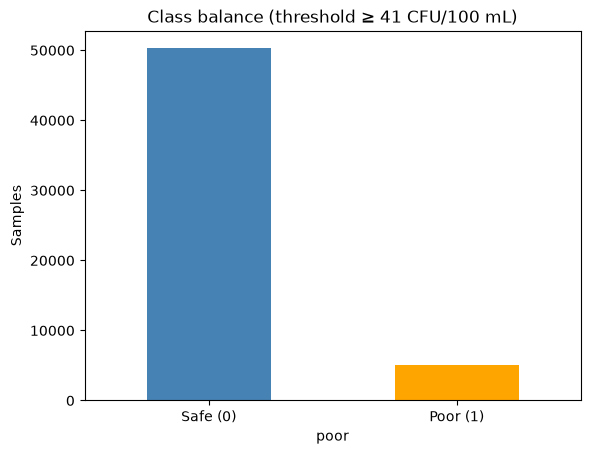

In [27]:
df['poor'].value_counts().sort_index().plot(kind='bar', color=['steelblue', 'orange'])
plt.xticks([0, 1], ['Safe (0)', 'Poor (1)'], rotation=0)
plt.ylabel('Samples')
plt.title(f'Class balance (threshold ≥ {THRESHOLD} CFU/100 mL)')
plt.show()

## 4. Quick checks

### 4.1 Sampling interval
**What it does:** Works out how many days apart each site's samples are.

**Output:** Summary stats of the gap in days (median should be ~6). This matters later: because samples are about a week apart, we can't see the exact day a beach recovers, so recovery times are approximate.

In [28]:
df.groupby('site')['date'].diff().dt.days.describe()

count    55319.000000
mean         6.878667
std          4.631884
min          1.000000
25%          6.000000
50%          6.000000
75%          7.000000
max        124.000000
Name: date, dtype: float64

## 5. Rainfall (SILO)
Daily rainfall from **SILO**. 13 files: 11 grid points (interpolated, 0.05° grid) and 2 real stations.

⚠️ Cite SILO as the data source (CC BY 4.0). ⚠️ To verify: SILO daily rain for date D should be the 24h to **9am on D**. Confirm in SILO's documentation and cite it.

### 5.1 Load the rainfall files
**What it does:** Reads each SILO .xlsx: finds the coordinates in the notes at the top, then the daily table below. Keeps the daily rainfall (mm).

**Output:** How many rain points loaded (should be 13) and a table of each point's coordinates and date range.

In [29]:
def load_silo(path):
    """Read one SILO xlsx -> (lat, lon, daily rainfall Series indexed by date)."""
    raw_xl = pd.read_excel(path, header=None)

    # Coordinates are in the notes block, e.g. 'Lat, Long: -33.80 151.25' or 'Lat: -33.6795 Long: 151.3076'
    notes = ' '.join(str(v) for v in raw_xl[0].head(40))
    lat, lon = map(float, re.search(r'Lat(?:, Long)?:\s*(-?\d+\.\d+)\s*(?:Long:)?\s*(-?\d+\.\d+)', notes).groups())

    # Table starts at the 'Date' header row, then a units row, then data
    h = raw_xl.index[raw_xl[0].astype(str).str.strip() == 'Date'][0]
    d = raw_xl.iloc[h + 2:].copy()
    d.columns = raw_xl.iloc[h].astype(str).str.strip()
    d = d[pd.to_numeric(d['Date'], errors='coerce').notna()]
    d['date'] = pd.to_datetime(d['Date'].astype(int).astype(str), format='%Y%m%d')
    return lat, lon, d.set_index('date')['Rain'].astype(float)

points = {}
for f in RAIN_FILES:
    lat, lon, rain = load_silo(f)
    points[f.split(' (')[0]] = {'lat': lat, 'lon': lon, 'rain': rain}

print(len(points), 'rain points loaded')
pd.DataFrame({name: {'lat': p['lat'], 'lon': p['lon'], 'from': p['rain'].index.min().date(),
                     'to': p['rain'].index.max().date(), 'blank days': p['rain'].isna().sum()}
              for name, p in points.items()}).T

13 rain points loaded


,lat,lon,from,to,blank days
Balgowlah,-33.8,151.25,2000-01-01,2026-10-07,0
Beacon Hill,-33.75,151.25,2000-01-01,2026-10-07,0
Belrose,-33.75,151.2,2000-01-01,2026-10-07,0
Dee Why,-33.75,151.3,2000-01-01,2026-10-07,0
Duffys Forest,-33.65,151.2,2000-01-01,2026-10-07,0
Ingleside,-33.7,151.25,2000-01-01,2026-10-07,0
Manly,-33.8,151.3,2000-01-01,2026-10-07,0
Mona Vale,-33.6795,151.3076,2000-01-01,2026-10-07,0
Newport,-33.65,151.3,2000-01-01,2026-10-07,0
North Narrabeen,-33.7,151.3,2000-01-01,2026-10-07,0


### 5.2 Match each swim site to its nearest rain point
**What it does:** Measures the straight-line distance from each swim site to every rain point and picks the closest. Several sites can share one rain point.

**Output:** A table: site → rain point and distance in km (all should be within ~3.5 km).

In [30]:
def nearest_point(lat, lon):
    dist = {name: 111.2 * np.hypot(p['lat'] - lat, (p['lon'] - lon) * np.cos(np.radians(lat)))
            for name, p in points.items()}
    best = min(dist, key=dist.get)
    return best, dist[best]

site_xy = df.groupby('site')[['Latitude', 'Longitude']].first()
site_map = pd.DataFrame(
    [(site, *nearest_point(r['Latitude'], r['Longitude'])) for site, r in site_xy.iterrows()],
    columns=['site', 'rain_point', 'dist_km']).set_index('site')
site_map.sort_values('rain_point').round(1)

,rain_point,dist_km
site,,
Fairlight Beach,Balgowlah,2.3
Sangrado Baths,Balgowlah,1.1
Forty Baskets Pool,Balgowlah,1.9
Gurney Crescent Baths,Balgowlah,1.5
Clontarf Pool,Balgowlah,0.7
Davidson Reserve,Belrose,2.0
North Curl Curl Beach,Dee Why,2.0
Dee Why Beach,Dee Why,0.4
Collaroy Beach,Dee Why,2.0


### 5.3 Rainfall features
**What it does:** Defines one function, `rain_features(daily_rain)`, that turns a daily rainfall series into the model's rainfall inputs:
- `rain_1d … rain_30d`: rain added up over the last 1, 2, 3, 5, 7, 14 and 30 days.
- `max_rain_7d`: the heaviest single day in the last 7.
- `days_since_rain`: days since the last day with at least `RAIN_EVENT_MM` mm (capped at 30).

It's a function so the **same code** builds the features for the training data and for the "no more rain" simulation in Section 12. The two can't drift apart.

**Output:** The first rows for one rain point (the first ~30 days of 2000 are blank in the long windows because there isn't enough history yet).

In [31]:
RAIN_COLS = [f'rain_{w}d' for w in RAIN_WINDOWS] + ['max_rain_7d', 'days_since_rain']

def rain_features(daily_rain):
    """Daily rain (Series indexed by date) -> DataFrame of rainfall features, one row per day."""
    r = daily_rain.asfreq('D')              # one row per day so rolling windows are in days
    out = pd.DataFrame(index=r.index)
    for w in RAIN_WINDOWS:
        out[f'rain_{w}d'] = r.rolling(w).sum()
    out['max_rain_7d'] = r.rolling(7).max()
    pos = np.arange(len(r))
    last_rain = pd.Series(np.where(r.values >= RAIN_EVENT_MM, pos, np.nan), index=r.index).ffill()
    out['days_since_rain'] = (pos - last_rain).fillna(DSR_CAP).clip(upper=DSR_CAP)
    return out

frames = []
for name, p in points.items():
    f = rain_features(p['rain'])
    f['rain_point'] = name
    frames.append(f)
rain_feats = pd.concat(frames).rename_axis('date').reset_index()
rain_feats[rain_feats['rain_point'] == list(points)[0]].head(8)

,date,rain_1d,rain_2d,rain_3d,rain_5d,rain_7d,rain_14d,rain_30d,max_rain_7d,days_since_rain,rain_point
0,2000-01-01,0.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,Balgowlah
1,2000-01-02,10.0,10.4,NaN,NaN,NaN,NaN,NaN,NaN,0.0,Balgowlah
2,2000-01-03,3.4,13.4,13.8,NaN,NaN,NaN,NaN,NaN,0.0,Balgowlah
3,2000-01-04,0.1,3.5,13.5,NaN,NaN,NaN,NaN,NaN,1.0,Balgowlah
4,2000-01-05,0.0,0.1,3.5,13.9,NaN,NaN,NaN,NaN,2.0,Balgowlah
5,2000-01-06,0.0,0.0,0.1,13.5,NaN,NaN,NaN,NaN,3.0,Balgowlah
6,2000-01-07,0.0,0.0,0.0,3.5,13.9,NaN,NaN,10.0,4.0,Balgowlah
7,2000-01-08,2.3,2.3,2.3,2.4,15.8,NaN,NaN,10.0,0.0,Balgowlah


### 5.4 Merge rainfall into the water quality data
**What it does:** Adds each sample's rain point, then joins the rainfall features on (rain point, date). Samples with blank long-window rainfall (only the first month of 2000) are dropped.

**Output:** Row count before and after the merge (the merge itself must not change the count), and how many early rows were dropped.

In [32]:
before = len(df)
df = df.drop(columns=RAIN_COLS + ['rain_point'], errors='ignore')
df['rain_point'] = df['site'].map(site_map['rain_point'])
df = df.merge(rain_feats, on=['rain_point', 'date'], how='left')
print(f'Rows before merge: {before} | after merge: {len(df)}')

n = len(df)
df = df.dropna(subset=RAIN_COLS).reset_index(drop=True)
print(f'Dropped {n - len(df)} rows with incomplete rainfall history (start of 2000)')

Rows before merge: 55361 | after merge: 55361
Dropped 184 rows with incomplete rainfall history (start of 2000)


### 5.5 Check: does rain relate to poor water?
**What it does:** Groups samples by rain in the previous 72h and shows the exceedance rate in each band.

**Output:** A table. Exceedance should climb steeply as rainfall increases, a good sign rainfall is a useful input.

In [33]:
bands = pd.cut(df['rain_3d'], [-0.1, 0, 5, 20, 50, np.inf], labels=['0', '0-5', '5-20', '20-50', '50+'])
(df.groupby(bands, observed=True)['poor'].agg(['count', 'mean'])
   .rename(columns={'count': 'samples', 'mean': 'exceed_rate'}).round(3))

,samples,exceed_rate
rain_3d,,
0,15495,0.029
0-5,20179,0.046
5-20,11617,0.117
20-50,5289,0.228
50+,2597,0.438


## 6. Lagoon flag and model inputs

### 6.1 Lagoon flag (beaches with a lagoon attached)
**What it does:** Adds `is_lagoon`: 1 if the site is a beach with a lagoon attached (or the lagoon itself), else 0. It's set by matching words from `LAGOON_KEYWORDS` against the site name, then adjusted by `LAGOON_EXACT` / `LAGOON_EXCLUDE`. Also builds `site_info`, a small table of each site's rain point, coordinates and flag, which the days-until-safe function uses later.

⚠️ **Check this table.** The flag is only as good as the list. Edit the lists in Section 1.1 and re-run.

**Output:** Every site, its flag, sample count and exceedance rate, then the average exceedance rate for flagged vs unflagged sites.

In [34]:
name_hit = df['site'].apply(lambda s: any(k.lower() in s.lower() for k in LAGOON_KEYWORDS))
df['is_lagoon'] = ((name_hit | df['site'].isin(LAGOON_EXACT)) & ~df['site'].isin(LAGOON_EXCLUDE)).astype(int)

site_info = df.groupby('site').agg(rain_point=('rain_point', 'first'), Latitude=('Latitude', 'first'),
                                   Longitude=('Longitude', 'first'), is_lagoon=('is_lagoon', 'first'))

check = (df.groupby('site').agg(is_lagoon=('is_lagoon', 'first'), samples=('poor', 'count'),
                                exceed_rate=('poor', 'mean')).round(3)
           .sort_values(['is_lagoon', 'exceed_rate'], ascending=False))
print('Flagged as lagoon:', int(check['is_lagoon'].sum()), 'of', len(check), 'sites')
display(check)
print('Exceedance rate: flagged', round(df.loc[df.is_lagoon == 1, 'poor'].mean(), 3),
      '| not flagged', round(df.loc[df.is_lagoon == 0, 'poor'].mean(), 3))

Flagged as lagoon: 6 of 42 sites


,is_lagoon,samples,exceed_rate
site,,,
Narrabeen Lagoon (Birdwood Park),1,1230,0.287
Queenscliff Beach,1,1571,0.144
North Curl Curl Beach,1,1574,0.075
North Narrabeen Beach,1,1571,0.066
Dee Why Beach,1,1574,0.064
South Curl Curl Beach,1,1571,0.052
Bilarong Reserve,0,722,0.324
Davidson Reserve,0,1218,0.245
Sangrado Baths,0,588,0.240


Exceedance rate: flagged 0.108 | not flagged 0.089


### 6.2 Do lagoon beaches stay poor for longer after rain?
**What it does:** Before modelling, looks straight at the data. Groups samples by days since the last rain day and compares the exceedance rate for lagoon vs non-lagoon beaches. If lagoon beaches stay poor for longer, their rate should stay higher as days-since-rain increases.

**Output:** A table: rows = days since rain, columns = not lagoon / lagoon. Samples are ~6 days apart, so expect rough patterns, and check the sample counts in the second table before trusting a row.

In [35]:
dsr_bins = pd.cut(df['days_since_rain'], [-1, 0, 1, 3, 7, 14, 30],
                  labels=['0 (rain today)', '1', '2-3', '4-7', '8-14', '15-30'])
rates = df.groupby([dsr_bins, 'is_lagoon'], observed=True)['poor'].mean().unstack().round(3)
counts = df.groupby([dsr_bins, 'is_lagoon'], observed=True)['poor'].count().unstack()
rates.columns = ['exceed rate: not lagoon', 'exceed rate: lagoon'][:len(rates.columns)]
counts.columns = ['samples: not lagoon', 'samples: lagoon'][:len(counts.columns)]
rates.join(counts)

,exceed rate: not lagoon,exceed rate: lagoon,samples: not lagoon,samples: lagoon
days_since_rain,,,,
0 (rain today),0.241,0.288,10655,1999
1,0.080,0.129,5657,1181
2-3,0.048,0.059,8860,1733
4-7,0.033,0.037,9690,1888
8-14,0.031,0.040,7195,1438
15-30,0.025,0.032,4029,852


### 6.3 Final feature list
**What it does:** Defines `add_model_features(d)`, which adds the non-rain inputs: month as sin/cos (so Dec and Jan are close) and two **lagoon × rain** interactions (`lagoon_x_rain_7d`, `lagoon_x_rain_30d`). The interactions let the linear model learn "long-term rain matters more at lagoon beaches". Tree models can find this on their own.

Like `rain_features`, it's a function so the simulation in Section 12 uses identical code.

`FEATURES` = rainfall + season + location (+ lagoon features if `USE_LAGOON`). **No previous-sample features.** Water temperature is also left out, because it's measured at the time of sampling.

**Output:** Summary stats for each feature.

In [36]:
BASE_FEATURES = RAIN_COLS + ['month_sin', 'month_cos', 'Latitude', 'Longitude']
LAGOON_FEATURES = ['is_lagoon', 'lagoon_x_rain_7d', 'lagoon_x_rain_30d']

def add_model_features(d):
    """Adds season + lagoon-interaction columns in place. d needs date, rain columns, is_lagoon."""
    d['month_sin'] = np.sin(2 * np.pi * d['date'].dt.month / 12)
    d['month_cos'] = np.cos(2 * np.pi * d['date'].dt.month / 12)
    d['lagoon_x_rain_7d'] = d['is_lagoon'] * d['rain_7d']
    d['lagoon_x_rain_30d'] = d['is_lagoon'] * d['rain_30d']
    return d

FEATURES = BASE_FEATURES + (LAGOON_FEATURES if USE_LAGOON else [])

df = add_model_features(df)
df['y_log'] = np.log1p(df['entero'])          # the regression target (log scale)
df = df.dropna(subset=FEATURES).reset_index(drop=True)
print('Rows:', len(df), '| features:', len(FEATURES))
df[FEATURES].describe().round(2)

Rows: 55177 | features: 16


,rain_1d,rain_2d,rain_3d,rain_5d,rain_7d,rain_14d,rain_30d,max_rain_7d,days_since_rain,month_sin,month_cos,Latitude,Longitude,is_lagoon,lagoon_x_rain_7d,lagoon_x_rain_30d
count,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00,55177.00
mean,3.08,6.67,9.85,16.56,22.90,46.21,98.78,13.58,5.20,0.03,0.05,-33.71,151.30,0.16,3.69,16.17
std,9.18,16.35,21.11,28.86,34.93,53.02,83.30,19.07,6.34,0.71,0.70,0.07,0.03,0.37,16.51,50.45
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-1.00,-1.00,-33.81,151.20,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.50,2.00,11.00,40.70,1.40,1.00,-0.50,-0.50,-33.79,151.29,0.00,0.00,0.00
50%,0.00,0.40,1.50,5.40,10.10,28.90,75.90,6.90,3.00,0.00,0.00,-33.70,151.30,0.00,0.00,0.00
75%,1.50,5.50,10.10,20.20,28.40,62.40,133.70,17.60,7.00,0.87,0.87,-33.64,151.31,0.00,0.00,0.00
max,171.20,199.40,299.30,389.20,417.50,692.90,867.10,186.40,30.00,1.00,1.00,-33.59,151.33,1.00,417.50,867.10


## 7. Splitting the data

### 7.1 Train / validation / test
**What it does:** Splits into train (60%), validation (20%) and test (20%).
- `SPLIT_MODE = 'date'`: earliest 60% of dates → train, next 20% → validation, latest 20% → test. The model is judged on the future, like a real tool.
- `SPLIT_MODE = 'random'`: stratified random split. Easier, but storms are shared between train and test, so scores are optimistic.

**Output:** Rows, date range, poor rate and lagoon share of each split.

In [37]:
if SPLIT_MODE == 'date':
    cut1 = df['date'].quantile(TRAIN_FRAC)
    cut2 = df['date'].quantile(TRAIN_FRAC + VAL_FRAC)
    train = df[df['date'] <= cut1].copy()
    val = df[(df['date'] > cut1) & (df['date'] <= cut2)].copy()
    test = df[df['date'] > cut2].copy()
else:
    df['band'] = pd.cut(df['entero'], bins=BAND_EDGES, labels=BAND_NAMES, right=False)
    trval, test = train_test_split(df, test_size=TEST_FRAC, stratify=df['band'], random_state=RANDOM_STATE)
    train, val = train_test_split(trval, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=trval['band'],
                                  random_state=RANDOM_STATE)
    train, val, test = train.copy(), val.copy(), test.copy()

splits = {'train': train, 'validation': val, 'test': test}
pd.DataFrame({name: {'rows': len(d), 'from': d['date'].min().date(), 'to': d['date'].max().date(),
                     'poor rate': round(d['poor'].mean(), 3), 'lagoon share': round(d['is_lagoon'].mean(), 3)}
              for name, d in splits.items()}).T

,rows,from,to,poor rate,lagoon share
train,33111,2000-01-31,2015-02-27,0.089,0.153
validation,11033,2015-03-03,2020-12-11,0.089,0.182
test,11033,2020-12-14,2026-09-21,0.105,0.182


### 7.2 Separate inputs (X) from answers (y)
**What it does:** `X` = feature columns. `y` = the **log enterococci count** (`log1p(entero)`). Counts are extremely skewed (most under 40, a few in the thousands), so on the raw scale a few spikes would dominate training. We convert back with `expm1` whenever we need CFU/100 mL.

**Output:** Shapes.

In [38]:
X_train, y_train = train[FEATURES], train['y_log']
X_val, y_val = val[FEATURES], val['y_log']
X_test, y_test = test[FEATURES], test['y_log']
print('X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)

X_train (33111, 16) | X_val (11033, 16) | X_test (11033, 16)


## 8. Train the regression models

### 8.1 Define the models
**What it does:** Three untrained regressors.
- **Ridge regression** (scaled inputs): a linear model, one weight per input. Simple and interpretable.
- **Random Forest:** 300 decision trees averaged.
- **XGBoost:** trees built one after another, each correcting the last.

**Output:** Nothing.

In [39]:
models = {
    'Ridge': Pipeline([('scale', StandardScaler()), ('reg', Ridge(alpha=1.0))]),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                           random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, random_state=RANDOM_STATE),
}

def reg_scores(y_true_log, y_pred_log):
    mae = mean_absolute_error(y_true_log, y_pred_log)
    return {'MAE (log)': mae,
            'RMSE (log)': np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
            'R²': r2_score(y_true_log, y_pred_log),
            'typical error (× or ÷)': np.exp(mae)}

### 8.2 Train on train, score on validation
**What it does:** Fits each model on the training set, scores it on training and validation. A big gap between train and validation error means overfitting.

How to read the scores (all on the log scale):
- **MAE (log):** average error. `typical error` turns it into a factor: 2.0 means predictions are usually within a factor of 2 (e.g. a true 40 is predicted somewhere between 20 and 80).
- **R²:** share of the variation explained (1 = perfect, 0 = no better than always guessing the average).

**Output:** A table per model.

In [40]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    tr = reg_scores(y_train, model.predict(X_train))
    va = reg_scores(y_val, model.predict(X_val))
    rows.append({'model': name, 'train MAE (log)': tr['MAE (log)'], 'val MAE (log)': va['MAE (log)'],
                 'val RMSE (log)': va['RMSE (log)'], 'val R²': va['R²'],
                 'val typical error (× or ÷)': va['typical error (× or ÷)']})
val_results = pd.DataFrame(rows).set_index('model').round(3)
val_results

,train MAE (log),val MAE (log),val RMSE (log),val R²,val typical error (× or ÷)
model,,,,,
Ridge,1.054,1.023,1.386,0.178,2.781
Random Forest,0.609,0.921,1.217,0.367,2.513
XGBoost,0.919,0.900,1.189,0.395,2.459


### 8.3 Pick the best model
**What it does:** Chooses the model with the lowest validation MAE. Decided **before** looking at the test set.

**Output:** The chosen model.

In [41]:
best = val_results['val MAE (log)'].idxmin()
print('Best on validation:', best)

Best on validation: XGBoost


## 9. Safe / not safe cutoff

### 9.1 Tune the cutoff on validation
**What it does:** The safe / not-safe call is a threshold on the predicted count: predicted **below** the cutoff = safe, otherwise not safe. The official level is 41, but regression models pull predictions towards the average and underestimate spikes, so a cutoff of exactly 41 can miss poor days. This scans cutoffs from 10 to 60 CFU/100 mL and picks the one with the best F1 for poor days **on the validation set** (the test set is not touched).

(You could instead tune for recall if missing a poor day matters more than a false alarm. For a swim-safety tool that's arguably the right call, so change `f1_score` to `recall_score` here if you prefer.)

**Output:** The chosen cutoff and a plot of F1 against cutoff.

Tuned cutoff: 15 CFU/100 mL (official threshold is 41)


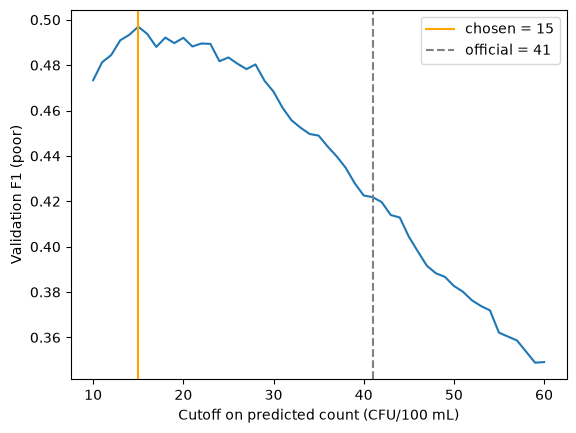

In [42]:
val_pred_cfu = np.expm1(models[best].predict(X_val))
cands = np.arange(10, 61)
f1s = [f1_score(val['poor'], (val_pred_cfu >= c).astype(int)) for c in cands]
CUTOFF = float(cands[int(np.argmax(f1s))])
print(f'Tuned cutoff: {CUTOFF:.0f} CFU/100 mL (official threshold is {THRESHOLD})')

plt.plot(cands, f1s)
plt.axvline(CUTOFF, color='orange', label=f'chosen = {CUTOFF:.0f}')
plt.axvline(THRESHOLD, color='grey', linestyle='--', label=f'official = {THRESHOLD}')
plt.xlabel('Cutoff on predicted count (CFU/100 mL)'); plt.ylabel('Validation F1 (poor)')
plt.legend(); plt.show()

## 10. Final results on the test set

### 10.1 Retrain on train + validation
**What it does:** Now that the choices are made, each model is retrained on train + validation together.

**Output:** Nothing printed.

In [43]:
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
for model in models.values():
    model.fit(X_trval, y_trval)
final_model = models[best]

### 10.2 How good are the predicted counts?
**What it does:** Scores each model's predicted count against the real lab result on the test set.

**Output:** MAE, RMSE, R² (log scale) and the typical error factor per model.

In [44]:
pd.DataFrame({name: reg_scores(y_test, m.predict(X_test)) for name, m in models.items()}).T.round(3)

,MAE (log),RMSE (log),R²,typical error (× or ÷)
Ridge,1.101,1.40,0.272,3.006
Random Forest,0.960,1.24,0.429,2.612
XGBoost,0.947,1.22,0.447,2.577


### 10.3 How good is the safe / not-safe call?
**What it does:** Turns each model's predicted count into safe / not safe, in two ways: at the official **41** and at the tuned **cutoff**. Compares with the real result. **Recall** = of the truly poor days, how many we caught. **Precision** = of the days we called poor, how many really were.

**Output:** A table per model and cutoff.

Note the tuned cutoff was chosen for the best model on validation, so for the other models it's just a reasonable alternative.

In [45]:
rows = []
for name, m in models.items():
    pred_cfu = np.expm1(m.predict(X_test))
    for label, c in [(f'official ({THRESHOLD})', THRESHOLD), (f'tuned ({CUTOFF:.0f})', CUTOFF)]:
        p = (pred_cfu >= c).astype(int)
        rows.append({'model': name, 'cutoff': label,
                     'recall (poor)': recall_score(test['poor'], p),
                     'precision (poor)': precision_score(test['poor'], p, zero_division=0),
                     'F1 (poor)': f1_score(test['poor'], p)})
pd.DataFrame(rows).set_index(['model', 'cutoff']).round(3)

recall (poor)  precision (poor)  F1 (poor)
model         cutoff                                                   
Ridge         official (41)          0.168             0.668      0.269
              tuned (15)             0.299             0.585      0.396
Random Forest official (41)          0.301             0.684      0.418
              tuned (15)             0.530             0.511      0.521
XGBoost       official (41)          0.294             0.718      0.417
              tuned (15)             0.513             0.520      0.516

### 10.4 Predicted vs actual
**What it does:** Plots the best model's predicted count against the real count for every test sample (log axes). Points on the diagonal are perfect. The dashed lines mark the official threshold.

**Output:** A scatter plot. Expect the cloud to be flatter than the diagonal: high counts are underpredicted and low ones overpredicted. That's the regression-to-the-mean effect, and it's why the cutoff was tuned.

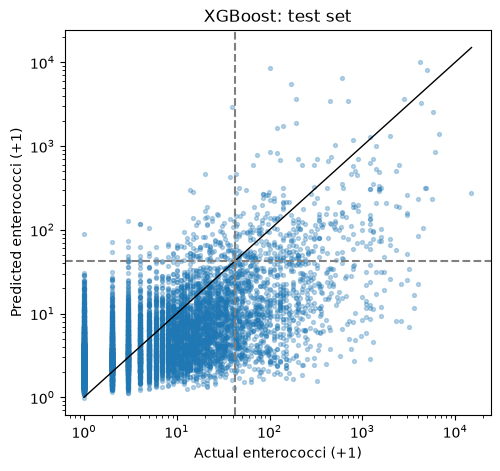

In [46]:
pred_test = np.expm1(final_model.predict(X_test))
plt.figure(figsize=(5.5, 5))
plt.scatter(test['entero'] + 1, pred_test + 1, s=8, alpha=0.3)
lim = [1, max(test['entero'].max(), pred_test.max()) + 1]
plt.plot(lim, lim, 'k-', lw=1)
plt.axvline(THRESHOLD + 1, color='grey', ls='--'); plt.axhline(THRESHOLD + 1, color='grey', ls='--')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Actual enterococci (+1)'); plt.ylabel('Predicted enterococci (+1)')
plt.title(f'{best}: test set'); plt.show()

### 10.5 Lagoon vs non-lagoon beaches
**What it does:** Splits the best model's test results by the lagoon flag, to see whether it does worse on one group.

**Output:** A table per group: samples, poor rate, typical error, and recall/precision at the tuned cutoff.

In [47]:
rows = []
for flag, s in test.assign(pred=pred_test).groupby('is_lagoon'):
    p = (s['pred'] >= CUTOFF).astype(int)
    rows.append({'group': 'lagoon' if flag else 'not lagoon', 'samples': len(s),
                 'poor rate': s['poor'].mean(),
                 'typical error (× or ÷)': np.exp(mean_absolute_error(np.log1p(s['entero']), np.log1p(s['pred']))),
                 'recall (poor)': recall_score(s['poor'], p, zero_division=0),
                 'precision (poor)': precision_score(s['poor'], p, zero_division=0)})
pd.DataFrame(rows).set_index('group').round(3)

,samples,poor rate,typical error (× or ÷),recall (poor),precision (poor)
group,,,,,
not lagoon,9022,0.100,2.555,0.481,0.502
lagoon,2011,0.128,2.680,0.626,0.577


## 11. Does the lagoon flag actually help?
One test split is noisy, so a small improvement could be luck. This runs a **rolling-origin test**: five times, train on everything before a date and test on the next slice of time (the test windows march forward through the data). Each time, fit the model **with** and **without** the lagoon features, on identical data. Then see how consistent the difference is.

**Output:** For each model: average error and R² with and without the flag, the average change, its spread across the five windows, and how many windows the flag won.

**How to read it:** if the average change is smaller than the spread, the flag isn't making a reliable difference. Note that latitude and longitude already identify each site, so tree models can partly work out which sites are lagoons without being told, and the flag may add little. The interaction features are more likely to help the Ridge model.

In [48]:
NO_LAGOON = BASE_FEATURES
WITH_LAGOON = BASE_FEATURES + LAGOON_FEATURES

qs = df['date'].quantile([0.5, 0.6, 0.7, 0.8, 0.9]).tolist() + [df['date'].max() + pd.Timedelta(days=1)]
rows = []
for k in range(5):
    tr = df[df['date'] < qs[k]]
    te = df[(df['date'] >= qs[k]) & (df['date'] < qs[k + 1])]
    for name, m in models.items():
        res = {}
        for tag, fl in [('without', NO_LAGOON), ('with', WITH_LAGOON)]:
            mm = clone(m).fit(tr[fl], tr['y_log'])
            p = mm.predict(te[fl])
            res[tag] = (mean_absolute_error(te['y_log'], p), r2_score(te['y_log'], p),
                        f1_score(te['poor'], (np.expm1(p) >= CUTOFF).astype(int)))
        rows.append({'fold': k, 'model': name,
                     'MAE without': res['without'][0], 'MAE with': res['with'][0],
                     'R² without': res['without'][1], 'R² with': res['with'][1],
                     'F1 without': res['without'][2], 'F1 with': res['with'][2]})
cmp = pd.DataFrame(rows)
cmp['MAE change'] = cmp['MAE with'] - cmp['MAE without']      # negative = lagoon flag helped
cmp['R² change'] = cmp['R² with'] - cmp['R² without']         # positive = lagoon flag helped
cmp['F1 change'] = cmp['F1 with'] - cmp['F1 without']         # positive = lagoon flag helped

summary = cmp.groupby('model').agg(**{
    'MAE without': ('MAE without', 'mean'), 'MAE with': ('MAE with', 'mean'),
    'MAE change (mean)': ('MAE change', 'mean'), 'MAE change (std)': ('MAE change', 'std'),
    'windows flag lowered MAE': ('MAE change', lambda s: int((s < 0).sum())),
    'R² change (mean)': ('R² change', 'mean'),
    'F1 change (mean)': ('F1 change', 'mean'),
}).round(4)
print('5 time windows; negative MAE change = lagoon flag helped')
summary

5 time windows; negative MAE change = lagoon flag helped


,MAE without,MAE with,MAE change (mean),MAE change (std),windows flag lowered MAE,R² change (mean),F1 change (mean)
model,,,,,,,
Random Forest,0.9412,0.9408,-0.0004,0.0008,3,0.0006,-0.0015
Ridge,1.0552,1.0543,-0.0009,0.0015,3,0.0022,0.0057
XGBoost,0.9234,0.9225,-0.0010,0.0014,4,0.0010,0.0003


## 12. Days until safe (assuming no more rain)
**What it does:** Defines `days_to_safe(site, start_date)`. It:
1. Takes the real rainfall up to `start_date`.
2. Sets rainfall to **0** for every day after that (the "no more rain" assumption).
3. Rebuilds the rainfall features for each of those days with the same `rain_features` function used for training. The storm gradually drops out of the 1, 2, 3, 5, 7, 14 and 30 day windows.
4. Predicts the count for each day and calls it safe if below the cutoff.
5. Reports the **first day from which it stays safe**.

Day 0 is `start_date` itself, so the function also answers "is it safe today?".

**Important:** this is an *earliest likely* time. If more rain falls, the clock resets. Recovery times also move in steps as rain windows empty out, and the model tends to underpredict spikes, so treat the answer as "roughly N days", not exact.

**Output:** Nothing printed (defines the functions).

In [49]:
def days_to_safe(site, start_date, model=None, cutoff=None, max_days=MAX_DAYS):
    """Predicted count per day from start_date onward, assuming no more rain.
    Returns (table, first_safe_day). first_safe_day is the first day from which every later day
    is also predicted safe, or None if that doesn't happen within max_days."""
    model = model or final_model
    cutoff = cutoff or CUTOFF
    start = pd.Timestamp(start_date).normalize()
    info = site_info.loc[site]
    rain = points[info['rain_point']]['rain']

    hist = rain.loc[start - pd.Timedelta(days=60): start]                 # real rain up to start
    future = pd.Series(0.0, index=pd.date_range(start + pd.Timedelta(days=1), periods=max_days))
    feats = rain_features(pd.concat([hist, future])).rename_axis('date').loc[start:].reset_index()

    feats['Latitude'], feats['Longitude'], feats['is_lagoon'] = info['Latitude'], info['Longitude'], info['is_lagoon']
    feats = add_model_features(feats)

    out = pd.DataFrame({'day': np.arange(len(feats)), 'date': feats['date'].dt.date,
                        'rain_3d': feats['rain_3d'].round(1), 'rain_14d': feats['rain_14d'].round(1),
                        'predicted CFU/100mL': np.expm1(model.predict(feats[FEATURES])).round(0)})
    out['safe'] = out['predicted CFU/100mL'] < cutoff
    stays_safe = np.logical_and.accumulate(out['safe'].values[::-1])[::-1]
    first = int(np.argmax(stays_safe)) if stays_safe.any() else None
    return out.set_index('day'), first

def plot_recovery(table, first, site, cutoff=None):
    cutoff = cutoff or CUTOFF
    plt.figure(figsize=(7, 3.5))
    plt.plot(table.index, table['predicted CFU/100mL'], marker='o')
    plt.axhline(cutoff, color='orange', ls='--', label=f'safe below {cutoff:.0f}')
    if first is not None:
        plt.axvline(first, color='green', ls=':', label=f'safe from day {first}')
    plt.xlabel('Days after start (no more rain)'); plt.ylabel('Predicted CFU/100 mL')
    plt.title(site); plt.legend(); plt.show()

### 12.1 Try it on a real storm
**What it does:** Picks the sample at the focus site in the test set with the most rain over the previous 3 days, then runs the days-until-safe simulation from that date. To try another site or date, call `days_to_safe('Site name', '2026-09-21')` yourself (site names must match the `site` column exactly).

**Output:** What was actually measured that day, the day-by-day predictions, the first safe day and a plot.

Narrabeen Lagoon (Birdwood Park) on 2022-03-10: measured 320 CFU/100 mL, 257 mm rain in the last 3 days


,date,rain_3d,rain_14d,predicted CFU/100mL,safe
day,,,,,
0,2022-03-10,257.3,615.0,241.0,False
1,2022-03-11,155.8,576.0,45.0,False
2,2022-03-12,0.5,502.2,19.0,False
3,2022-03-13,0.0,471.7,16.0,False
4,2022-03-14,0.0,463.1,12.0,True
5,2022-03-15,0.0,446.8,12.0,True
6,2022-03-16,0.0,422.5,10.0,True
7,2022-03-17,0.0,369.1,10.0,True
8,2022-03-18,0.0,350.3,10.0,True


Not predicted to be safe within 14 days (assuming no more rain).


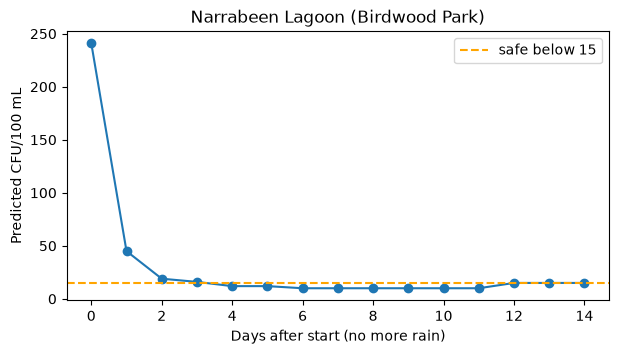

In [50]:
cand = test[test['site'] == FOCUS_SITE]
if cand.empty:
    cand = test
ex = cand.sort_values('rain_3d').iloc[-1]
print(f"{ex['site']} on {ex['date'].date()}: measured {ex['entero']:.0f} CFU/100 mL, "
      f"{ex['rain_3d']:.0f} mm rain in the last 3 days")

table, first = days_to_safe(ex['site'], ex['date'])
display(table)
if first is None:
    print(f'Not predicted to be safe within {MAX_DAYS} days (assuming no more rain).')
elif first == 0:
    print('Predicted safe to swim on the day.')
else:
    print(f'Predicted safe from day {first} onward (if no more rain falls).')
plot_recovery(table, first, ex['site'])

## 13. Back-test the days-until-safe idea
**What it does:** Checks whether the "no more rain" recovery prediction matches reality. It takes every **poor** sample in the test set, and the **next** sample at the same site, and keeps only cases where:
- the next sample is within `MAX_DAYS`, and
- little rain fell in between (less than `DRY_MM` mm), so the "no more rain" assumption actually holds.

For each, the model predicts whether the beach is safe by the next sample's date, and that's compared with the real next result.

Samples are about 6 days apart, so this only tests recovery at that coarse resolution. It can't verify "safe on day 2". And after filtering for dry gaps, there may be few cases, so check the count.

**Output:** The number of cases, the share that really were safe by the next sample vs the share the model predicted, a confusion table, and how often they agree.

In [51]:
g = df.groupby('site')
nxt = df.assign(next_date=g['date'].shift(-1), next_entero=g['entero'].shift(-1))
cand = nxt.loc[test.index]
cand = cand[(cand['entero'] >= THRESHOLD) & cand['next_date'].notna()]

rows = []
for _, r in cand.iterrows():
    gap = int((r['next_date'] - r['date']).days)
    if gap < 1 or gap > MAX_DAYS:
        continue
    rain = points[site_info.loc[r['site'], 'rain_point']]['rain']
    if rain.loc[r['date'] + pd.Timedelta(days=1): r['next_date']].sum() >= DRY_MM:
        continue                                            # it rained: 'no more rain' doesn't apply
    tbl, first = days_to_safe(r['site'], r['date'], max_days=gap)
    rows.append({'site': r['site'], 'date': r['date'].date(), 'gap_days': gap,
                 'actually safe at next sample': int(r['next_entero'] < THRESHOLD),
                 'model: safe by next sample': int(tbl.loc[gap, 'safe']),
                 'model: first safe day': first})
bt = pd.DataFrame(rows)

print(f'Poor samples followed by a dry gap (≤{MAX_DAYS} days, <{DRY_MM} mm): {len(bt)}')
if len(bt):
    print('Actually safe by next sample:', round(bt['actually safe at next sample'].mean(), 3))
    print('Model says safe by next sample:', round(bt['model: safe by next sample'].mean(), 3))
    print('Agreement:', round((bt['actually safe at next sample'] == bt['model: safe by next sample']).mean(), 3))
    display(pd.crosstab(bt['actually safe at next sample'], bt['model: safe by next sample'],
                        rownames=['actual'], colnames=['model']))
bt.head(10)

Poor samples followed by a dry gap (≤14 days, <5 mm): 280
Actually safe by next sample: 0.854
Model says safe by next sample: 0.993
Agreement: 0.846


model,0,1
actual,,
0,0,41
1,2,237


,site,date,gap_days,actually safe at next sample,model: safe by next sample,model: first safe day
0,Avalon Beach,2022-10-25,6,1,1,1.0
1,Barrenjoey Beach,2021-02-23,6,1,1,0.0
2,Barrenjoey Beach,2021-04-13,6,1,1,0.0
3,Barrenjoey Beach,2022-10-13,6,1,1,0.0
4,Barrenjoey Beach,2022-11-23,6,1,1,0.0
5,Barrenjoey Beach,2023-04-04,7,0,1,1.0
6,Barrenjoey Beach,2024-04-10,5,1,1,0.0
7,Barrenjoey Beach,2026-04-13,4,1,1,0.0
8,Bayview Baths,2022-10-25,6,0,1,2.0
9,Bayview Baths,2022-10-31,4,1,1,0.0


## Notes and limitations
- **Rain only.** With no previous-sample inputs, the model can't know the beach's current state, so it will be less accurate than the original classifier. That's the price of working from a forecast alone.
- **Peaks are underestimated.** Regression pulls predictions towards the average. Predicting on a log scale and tuning the cutoff reduce this but don't remove it, so "days until safe" tends to be on the optimistic side. Check the back-test in Section 13.
- **Coarse recovery timing.** Samples are ~6 days apart, so real recovery times can't be seen at day resolution. Predicted recoveries come from how the rain windows empty out.
- **The lagoon flag overlaps with location.** Latitude and longitude identify each site, so the flag may add little beyond them. Section 11 tests this.
- **Lagoon list is a guess.** Check Section 6.1 and edit `LAGOON_KEYWORDS` / `LAGOON_EXACT` / `LAGOON_EXCLUDE`.
- **A real tool** would need a rainfall *forecast* for future days. "No more rain" is the best case.